# IND320 Assignment 1

## GitHub and Streamlit app
GitHub repository can be found [Here](https://github.com/ptilrem/ptilrem-D2D-SLapp/tree/main)

Streamlit app can be found [Here](https://ptilrem-d2d-slapp.streamlit.app/)

## Tasks

### Imports and Preparation

In [1]:
import os
import sys
import re
from datetime import datetime, timezone, timedelta
from xml.etree import ElementTree as ET

import requests
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

# Credentials are kept in a local .env file, never uploaded to GitHub.
load_dotenv(override=True)
ENTSOE_TOKEN = os.getenv("ENTSOE_TOKEN", "").strip()
MONGODB_URI = os.getenv("MONGODB_URI", "").strip()

print("Python:", sys.version.split()[0])
print("ENTSO-E token configured:", bool(ENTSOE_TOKEN))
print("MongoDB URI configured:", bool(MONGODB_URI))

Python: 3.12.10
ENTSO-E token configured: False
MongoDB URI configured: True


### Spark-Cassandra setup

In [2]:
# All environment configuration must occur before SparkSession is created.
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from cassandra.cluster import Cluster

# Spark 3.5-compatible Cassandra connector; configure at first Spark start.
spark = (SparkSession.builder
    .appName("IND320_Assignment2")
    .master("local[2]")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

print("Imported PySpark:", pyspark.__version__)
print("Running Spark JVM:", spark.version)
print("Connector:", spark.sparkContext.getConf().get("spark.jars.packages"))

Imported PySpark: 3.5.9
Running Spark JVM: 3.5.1
Connector: com.datastax.spark:spark-cassandra-connector_2.12:3.5.1


In [3]:
# Connect to local Cassandra
cluster = Cluster(["127.0.0.1"], port=9042)
cas = cluster.connect()
cas.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320_a2
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Partition by one connection/direction/day, clustering by observation time.
cas.execute("""
CREATE TABLE IF NOT EXISTS ind320_a2.entsoe_flows (
    connection text,
    direction text,
    date_utc text,
    timestamp_utc timestamp,
    power_mw double,
    duration_hours double,
    energy_mwh double,
    PRIMARY KEY ((connection, direction, date_utc), timestamp_utc)
)
""")
print("Cassandra table ready: ind320_a2.entsoe_flows")

Cassandra table ready: ind320_a2.entsoe_flows


In [4]:
# Tiny end-to-end smoke check without changing the assignment's raw table.
cas.execute("""
CREATE TABLE IF NOT EXISTS ind320_a2.connection_test
(id int PRIMARY KEY, name text)
""")
smoke_df = spark.createDataFrame([(1, "Spark -> Cassandra works")], ["id", "name"])
(smoke_df.write.format("org.apache.spark.sql.cassandra")
 .options(table="connection_test", keyspace="ind320_a2")
 .mode("append").save())
(spark.read.format("org.apache.spark.sql.cassandra")
 .options(table="connection_test", keyspace="ind320_a2")
 .load().show(truncate=False))

+---+------------------------+
|id |name                    |
+---+------------------------+
|1  |Spark -> Cassandra works|
+---+------------------------+



### NVE API

In [5]:
# Download current NVE datasets directly from the official API.
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

def get_nve(endpoint):
    response = requests.get(f"{NVE_BASE}/{endpoint}", timeout=90)
    response.raise_for_status()
    return response.json()

nve_records = get_nve("HentOffentligData")
nve_areas = get_nve("HentOmråder")

print("Reservoir data response:", type(nve_records).__name__)
print("Area data response:", type(nve_areas).__name__)
print("Number of reservoir records:", len(nve_records))
print("First record:", nve_records[0] if isinstance(nve_records, list) and nve_records else "Inspect response structure")

Reservoir data response: list
Area data response: list
Number of reservoir records: 14922
First record: {'dato_Id': '1995-09-03', 'omrType': 'EL', 'omrnr': 4, 'iso_aar': 1995, 'iso_uke': 35, 'fyllingsgrad': 0.94472134, 'kapasitet_TWh': 21.079208, 'fylling_TWh': 19.913979, 'neste_Publiseringsdato': '0001-01-01T00:00:00', 'fyllingsgrad_forrige_uke': 0.9368882, 'endring_fyllingsgrad': 0.007833123}


In [6]:
# Convert API's long-format weekly records to a documented DataFrame.
nve_df = pd.DataFrame(nve_records)
required = {"iso_aar", "iso_uke", "omrType", "omrnr", "fyllingsgrad"}
missing = required - set(nve_df.columns)
if missing:
    raise ValueError(f"NVE response columns differ from the documented schema: {missing}")

# ISO year/week + weekday 1 = Monday of that ISO week.
nve_df["week_date"] = pd.to_datetime(
    nve_df["iso_aar"].astype(int).astype(str) + "-W" +
    nve_df["iso_uke"].astype(int).astype(str).str.zfill(2) + "-1",
    format="%G-W%V-%u", errors="coerce"
)
for col in ["fyllingsgrad", "kapasitet_TWh", "fylling_TWh"]:
    if col in nve_df.columns:
        nve_df[col] = pd.to_numeric(nve_df[col], errors="coerce")

# NVE sometimes expresses a relative fill fraction in [0,1].
# Display percentage explicitly in the charts if that is the observed scale.
nve_df["fill_percent"] = nve_df["fyllingsgrad"]
if nve_df["fill_percent"].dropna().max() <= 1.05:
    nve_df["fill_percent"] *= 100

print("NVE area types:", nve_df["omrType"].value_counts().to_dict())
print("Date range:", nve_df["week_date"].min(), "to", nve_df["week_date"].max())
display(nve_df.head())

NVE area types: {'EL': 8290, 'VASS': 4974, 'NO': 1658}
Date range: 1995-01-02 00:00:00 to 2026-10-05 00:00:00


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad,week_date,fill_percent
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833,1995-08-28,94.472134
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046,2020-11-09,97.436064
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694,2011-08-22,78.649880
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157,1998-06-29,79.396940
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301,2011-03-21,30.082030


In [7]:
# NVE's area directory is organized into land / elspot / vassdrag.
# Build an optional descriptive lookup table for Streamlit radio selections.
area_frames = []
if isinstance(nve_areas, dict):
    for category, entries in nve_areas.items():
        if isinstance(entries, list):
            section = pd.DataFrame(entries)
            if not section.empty:
                section["api_category"] = category
                area_frames.append(section)
nve_area_df = pd.concat(area_frames, ignore_index=True) if area_frames else pd.DataFrame()
print("Area columns:", list(nve_area_df.columns))
display(nve_area_df.head(12))

Area columns: []


""


In [8]:
# Keep the original Assignment 1 English column names for consistent plots.
column_rename_dict = {
    "dato_Id": "date_id",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_percentage",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publish_date",
    "fyllingsgrad_forrige_uke": "fill_percentage_last_week",
    "endring_fyllingsgrad": "change_fill_percentage",
}

# Build a separate DataFrame so the other Assignment 2 NVE cells still use nve_df.
reservoir_df = nve_df.rename(columns=column_rename_dict).copy()

# Prefer the original publication/observation date where included in the API.
# The ISO-week-derived date provides a fallback if NVE omits date_id.
if "date_id" in reservoir_df.columns:
    reservoir_df["date_id"] = pd.to_datetime(reservoir_df["date_id"], errors="coerce")
else:
    reservoir_df["date_id"] = pd.to_datetime(reservoir_df["week_date"], errors="coerce")

measurement_columns = [
    "fill_percentage",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_percentage_last_week",
    "change_fill_percentage",
]
required = ["date_id", "area_type", "area_number"] + measurement_columns
missing = [c for c in required if c not in reservoir_df.columns]
if missing:
    raise ValueError(f"These expected NVE fields are missing: {missing}")

for col in measurement_columns:
    reservoir_df[col] = pd.to_numeric(reservoir_df[col], errors="coerce")

reservoir_df = (reservoir_df.dropna(subset=["date_id"])
                .sort_values(["date_id", "area_type", "area_number"]))
print("Source: NVE Magasinstatistikk API (not a local CSV)")
print("Observations:", len(reservoir_df))
print("From:", reservoir_df["date_id"].min(), "to:", reservoir_df["date_id"].max())
display(reservoir_df.head())


Source: NVE Magasinstatistikk API (not a local CSV)
Observations: 14922
From: 1995-01-08 00:00:00 to: 2026-10-11 00:00:00


,date_id,area_type,area_number,iso_year,iso_week,fill_percentage,capacity_TWh,stored_energy_TWh,next_publish_date,fill_percentage_last_week,change_fill_percentage,week_date,fill_percent
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869,1995-01-02,61.757370
7282,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657,1995-01-02,63.094735
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349,1995-01-02,60.237580
3014,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484,1995-01-02,55.886410
3111,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160,1995-01-02,61.644780


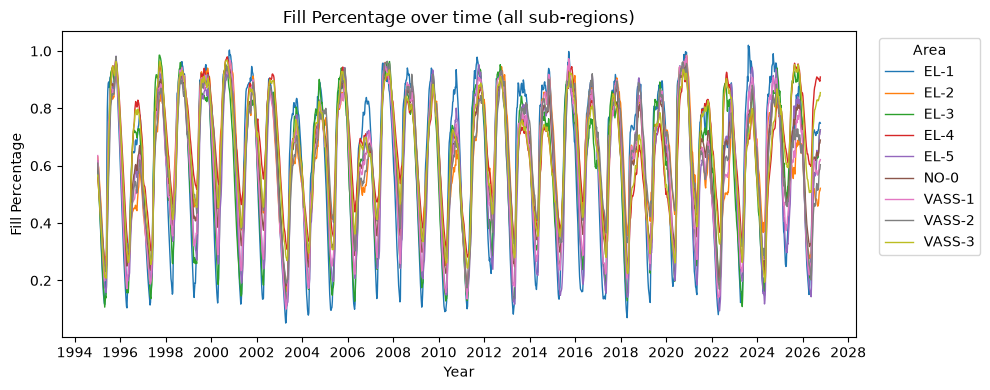

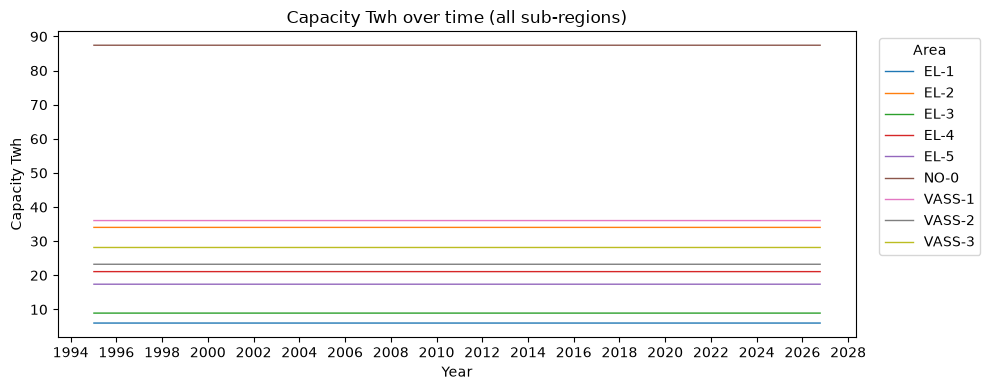

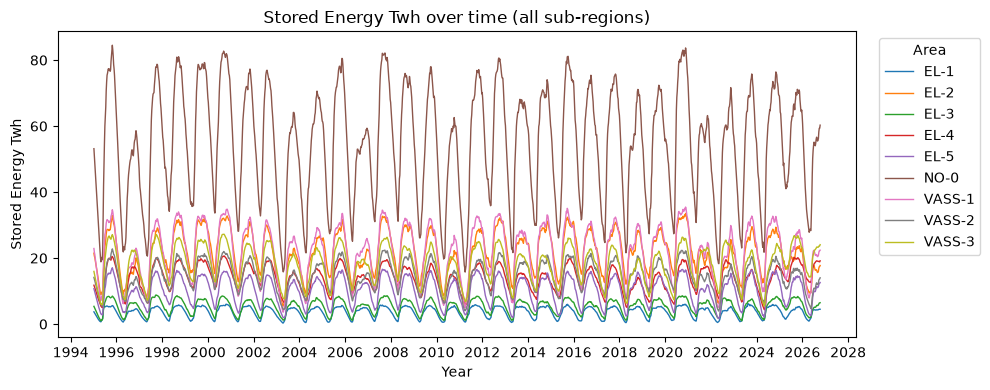

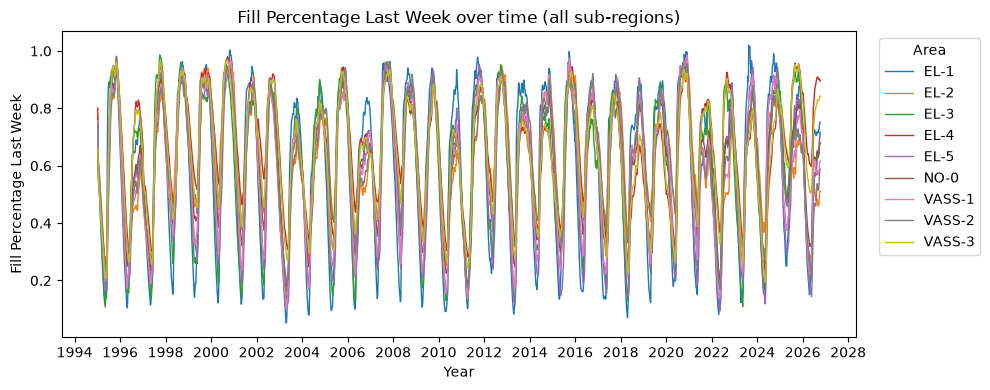

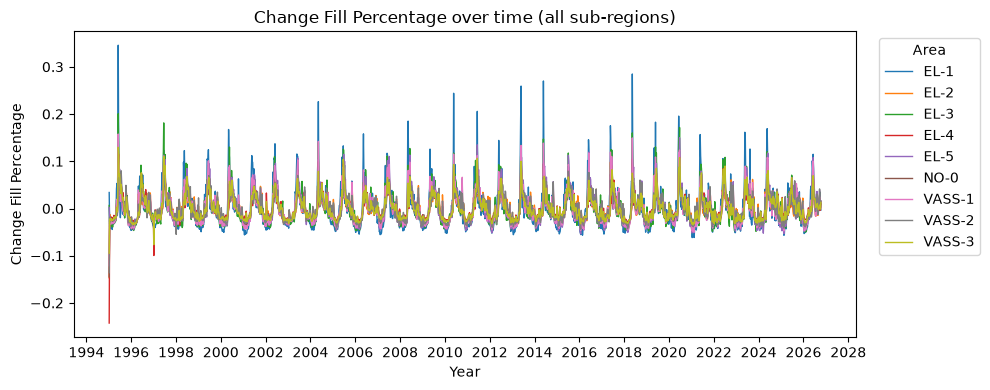

In [9]:
import matplotlib.dates as mdates

# These are the same five measurements as in my Assignment 1.
# True:  one line per area type and number (clearer, avoids joining regions).
# False: group only by area type, just like the original notebook.
SEPARATE_AREA_NUMBERS = True
area_grouping = ["area_type", "area_number"] if SEPARATE_AREA_NUMBERS else ["area_type"]

for col in measurement_columns:
    fig, ax = plt.subplots(figsize=(10, 4))

    for area_key, group in reservoir_df.groupby(area_grouping):
        label = "-".join(map(str, area_key)) if isinstance(area_key, tuple) else str(area_key)
        ax.plot(group["date_id"], group[col], label=label, linewidth=1.0)

    # As in Assignment 1: display a year label every two years.
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(f'{col.replace("_", " ").title()} over time (all sub-regions)')
    ax.set_xlabel("Year")
    ax.set_ylabel(col.replace("_", " ").title())
    ax.legend(title="Area" if SEPARATE_AREA_NUMBERS else "Area type",
              bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


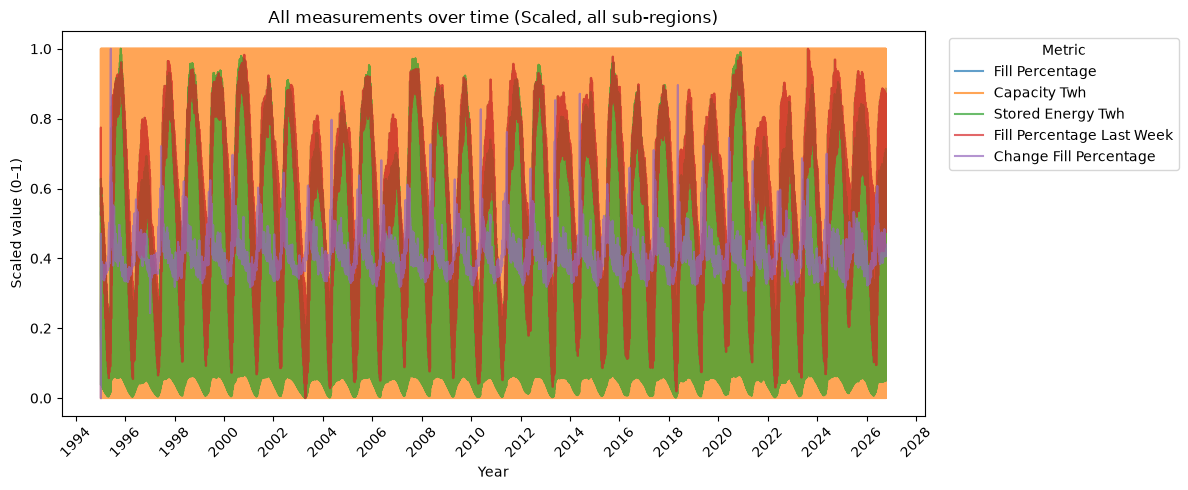

In [10]:
# Recreate the Assignment 1 combined plot, scaling each measurement
# to [0, 1] so values with different units can appear together.
# This uses all subregions, as the original plot did.
df_scaled = reservoir_df.copy()
for col in measurement_columns:
    col_min, col_max = reservoir_df[col].min(), reservoir_df[col].max()
    if pd.isna(col_min) or pd.isna(col_max) or col_max == col_min:
        df_scaled[col] = 0.0  # Avoid division by zero for a constant column.
    else:
        df_scaled[col] = (reservoir_df[col] - col_min) / (col_max - col_min)

fig, ax = plt.subplots(figsize=(12, 5))
for col in measurement_columns:
    ax.plot(df_scaled["date_id"], df_scaled[col],
            label=col.replace("_", " ").title(), alpha=0.7)

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
ax.set_title("All measurements over time (Scaled, all sub-regions)")
ax.set_xlabel("Year")
ax.set_ylabel("Scaled value (0–1)")
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### ENTSO-E

In [11]:
DATA_MODE = "demo"       # Change to "api" for measured ENTSO-E data.

# ENTSO-E area codes for Norway and its foreign bidding-zone neighbours.
EIC = {
    "NO_1": "10YNO-1--------2", "NO_2": "10YNO-2--------T",
    "NO_3": "10YNO-3--------J", "NO_4": "10YNO-4--------9",
    "SE_1": "10Y1001A1001A44P", "SE_2": "10Y1001A1001A45N",
    "SE_3": "10Y1001A1001A46L", "DK_1": "10YDK-1--------W",
    "NL": "10YNL----------L", "DE_LU": "10Y1001A1001A82H",
    "GB": "10YGB----------A", "FI": "10YFI-1--------U",
}

# Nine international zone borders. Domestic NO–NO connections are excluded.
CONNECTIONS = [
    ("NO1-SE3", "NO_1", "SE_3"),
    ("NO2-DK1", "NO_2", "DK_1"),
    ("NO2-NL", "NO_2", "NL"),
    ("NO2-DE-LU", "NO_2", "DE_LU"),
    ("NO2-GB", "NO_2", "GB"),
    ("NO3-SE2", "NO_3", "SE_2"),
    ("NO4-SE1", "NO_4", "SE_1"),
    ("NO4-SE2", "NO_4", "SE_2"),
    ("NO4-FI", "NO_4", "FI"),
]

# The demonstration is deliberately smaller; real API mode uses all nine.
RUN_CONNECTIONS = CONNECTIONS[:3] if DATA_MODE == "demo" else CONNECTIONS
END_UTC = pd.Timestamp.now(tz="UTC").normalize()
START_UTC = END_UTC - pd.DateOffset(years=2)

if DATA_MODE not in ("demo", "api"):
    raise ValueError('DATA_MODE must be "demo" or "api"')

raw_table = "entsoe_flows_demo" if DATA_MODE == "demo" else "entsoe_flows"
mongo_collection = "entsoe_daily_flows_demo" if DATA_MODE == "demo" else "entsoe_daily_flows"

print("Data source:", DATA_MODE)
print("Dates:", START_UTC.date(), "to", END_UTC.date(), "(exclusive)")
print("Borders:", [item[0] for item in RUN_CONNECTIONS])
if DATA_MODE == "demo":
    print("WARNING: All electricity measurements in this run are fictional.")

Data source: demo
Dates: 2024-10-20 to 2026-10-20 (exclusive)
Borders: ['NO1-SE3', 'NO2-DK1', 'NO2-NL']


In [12]:
# The API returns XML. These helpers convert its individual MW readings to rows.
def monthly_windows(start, end):
    """API calls cover one month at a time, avoiding overly long requests."""
    cursor = start
    while cursor < end:
        next_month = (cursor + pd.offsets.MonthBegin(1)).normalize()
        window_end = min(next_month, end)
        yield cursor, window_end
        cursor = window_end


def entsoe_xml(from_area, to_area, start, end):
    """Request physical cross-border flow (A11); do not print the secret token."""
    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType": "A11",
        "out_Domain": EIC[from_area],
        "in_Domain": EIC[to_area],
        "periodStart": start.strftime("%Y%m%d%H%M"),
        "periodEnd": end.strftime("%Y%m%d%H%M"),
    }
    try:
        response = requests.get("https://web-api.tp.entsoe.eu/api", params=params, timeout=90)
    except requests.RequestException:
        # Some HTTP exceptions include the request URL and its API token.
        raise RuntimeError("ENTSO-E request failed; check connectivity.") from None
    if response.status_code != 200:
        raise RuntimeError(f"ENTSO-E HTTP {response.status_code}: check API access and area codes.")
    return response.text


def children(node, tag_name):
    """Ignore XML namespace prefixes."""
    return [item for item in node if item.tag.split("}")[-1] == tag_name]


def child_text(node, tag_name):
    found = children(node, tag_name)
    return found[0].text if found else None


def parse_entsoe_xml(xml_text, connection, direction):
    """Extract dated power readings and calculate the energy in each interval."""
    root = ET.fromstring(xml_text)
    if root.tag.split("}")[-1] == "Acknowledgement_MarketDocument":
        # The API sends this when no data exist for a requested period.
        return []

    records = []
    for series in root.iter():
        if series.tag.split("}")[-1] != "TimeSeries":
            continue
        for period in children(series, "Period"):
            interval_node = children(period, "timeInterval")[0]
            start_time = datetime.fromisoformat(
                child_text(interval_node, "start").replace("Z", "+00:00")
            ).astimezone(timezone.utc)
            resolution = child_text(period, "resolution")
            match = re.fullmatch(r"PT(?:(\d+)H)?(?:(\d+)M)?", resolution or "")
            if not match:
                raise ValueError(f"Unsupported time resolution: {resolution}")
            hours = int(match.group(1) or 0) + int(match.group(2) or 0) / 60
            if hours <= 0:
                raise ValueError("Time resolution must be positive")

            for point in children(period, "Point"):
                position = int(child_text(point, "position"))
                power = float(child_text(point, "quantity"))
                timestamp = start_time + timedelta(hours=(position - 1) * hours)
                records.append({
                    "connection": connection,
                    "direction": direction,
                    "date_utc": timestamp.strftime("%Y-%m-%d"),
                    "timestamp_utc": timestamp.replace(tzinfo=None),
                    "power_mw": power,
                    "duration_hours": float(hours),
                    "energy_mwh": power * hours,
                })
    return records

### Insert data into Cassandra using Spark

In [13]:
# Only demo mode needs an additional Cassandra table. Earlier section created the real table.
if DATA_MODE == "demo":
    cas.execute("""
    CREATE TABLE IF NOT EXISTS ind320_a2.entsoe_flows_demo (
        connection text,
        direction text,
        date_utc text,
        timestamp_utc timestamp,
        power_mw double,
        duration_hours double,
        energy_mwh double,
        PRIMARY KEY ((connection, direction, date_utc), timestamp_utc)
    )
    """)

# Explicit Spark schema avoids guessing data types before writing to Cassandra.
FLOW_SCHEMA = T.StructType([
    T.StructField("connection", T.StringType()),
    T.StructField("direction", T.StringType()),
    T.StructField("date_utc", T.StringType()),
    T.StructField("timestamp_utc", T.TimestampType()),
    T.StructField("power_mw", T.DoubleType()),
    T.StructField("duration_hours", T.DoubleType()),
    T.StructField("energy_mwh", T.DoubleType()),
])


def write_to_cassandra(rows):
    """Write one batch with Spark; empty API responses produce no rows."""
    if rows:
        frame = spark.createDataFrame(rows, schema=FLOW_SCHEMA)
        (frame.write.format("org.apache.spark.sql.cassandra")
         .options(table=raw_table, keyspace="ind320_a2")
         .mode("append").save())


rows_written = 0
if DATA_MODE == "demo":
    for border_index, (connection, _, _) in enumerate(RUN_CONNECTIONS):
        for direction in ("Into Norway", "Out of Norway"):
            rows = []
            for day in pd.date_range(START_UTC, END_UTC, freq="D", inclusive="left"):
                # Fictional daily-average MW values, chosen only for testing.
                power = 150 + border_index * 55 + (35 if direction == "Out of Norway" else 0)
                power += (day.dayofyear % 30) * 3
                timestamp = day.tz_localize(None).to_pydatetime()
                rows.append({
                    "connection": connection, "direction": direction,
                    "date_utc": day.strftime("%Y-%m-%d"),
                    "timestamp_utc": timestamp,
                    "power_mw": float(power), "duration_hours": 24.0,
                    "energy_mwh": float(power * 24),
                })
            write_to_cassandra(rows)
            rows_written += len(rows)
            print(f"DEMO: {connection}, {direction}: {len(rows)} synthetic rows")

else:
    if not ENTSOE_TOKEN:
        raise RuntimeError("Add ENTSOE_TOKEN to your .env file before selecting api mode.")

    for connection, norway, neighbour in RUN_CONNECTIONS:
        for direction, from_area, to_area in (
            ("Out of Norway", norway, neighbour),
            ("Into Norway", neighbour, norway),
        ):
            for start, end in monthly_windows(START_UTC, END_UTC):
                xml = entsoe_xml(from_area, to_area, start, end)
                rows = parse_entsoe_xml(xml, connection, direction)
                write_to_cassandra(rows)
                rows_written += len(rows)
                print(f"API: {connection}, {direction}, {start.date()}: {len(rows)} rows")

print(f"Written to Cassandra table {raw_table}: {rows_written:,} rows")

DEMO: NO1-SE3, Into Norway: 730 synthetic rows
DEMO: NO1-SE3, Out of Norway: 730 synthetic rows
DEMO: NO2-DK1, Into Norway: 730 synthetic rows
DEMO: NO2-DK1, Out of Norway: 730 synthetic rows
DEMO: NO2-NL, Into Norway: 730 synthetic rows
DEMO: NO2-NL, Out of Norway: 730 synthetic rows
Written to Cassandra table entsoe_flows_demo: 4,380 rows


### Extracting relevant columns from Cassandra with Spark

In [14]:
raw_spark = (spark.read.format("org.apache.spark.sql.cassandra")
             .options(table=raw_table, keyspace="ind320_a2")
             .load())

# Filter out observations from older runs when using a rolling two-year period.
start_date = START_UTC.strftime("%Y-%m-%d")
end_date = END_UTC.strftime("%Y-%m-%d")

# Spark selects only needed columns, then sums MWh per day and direction.
daily_spark = (raw_spark
    .select("connection", "direction", "date_utc", "energy_mwh")
    .filter((F.col("date_utc") >= start_date) & (F.col("date_utc") < end_date))
    .groupBy("connection", "direction", "date_utc")
    .agg(F.sum("energy_mwh").alias("energy_mwh"))
    .withColumn("year", F.year(F.to_date("date_utc")))
    .withColumn("month", F.month(F.to_date("date_utc"))))

daily_spark.show(6, truncate=False)
daily_pd = daily_spark.toPandas()
if daily_pd.empty:
    raise RuntimeError("No rows found. Run Section 5 to import the data first.")

daily_pd["date"] = pd.to_datetime(daily_pd["date_utc"], utc=True)
daily_pd["data_source"] = "synthetic" if DATA_MODE == "demo" else "ENTSO-E API"
print("Daily rows:", len(daily_pd))
print("Earliest/latest dates:", daily_pd["date"].min(), daily_pd["date"].max())

+----------+-------------+----------+----------+----+-----+
|connection|direction    |date_utc  |energy_mwh|year|month|
+----------+-------------+----------+----------+----+-----+
|NO2-DK1   |Out of Norway|2025-12-05|6408.0    |2025|12   |
|NO2-DK1   |Into Norway  |2026-04-17|6144.0    |2026|4    |
|NO2-NL    |Out of Norway|2026-01-25|8880.0    |2026|1    |
|NO1-SE3   |Into Norway  |2026-01-20|5040.0    |2026|1    |
|NO2-DK1   |Out of Norway|2026-06-20|7272.0    |2026|6    |
|NO1-SE3   |Into Norway  |2026-01-11|4392.0    |2026|1    |
+----------+-------------+----------+----------+----+-----+
only showing top 6 rows

Daily rows: 4380
Earliest/latest dates: 2024-10-20 00:00:00+00:00 2026-10-19 00:00:00+00:00


### Plots

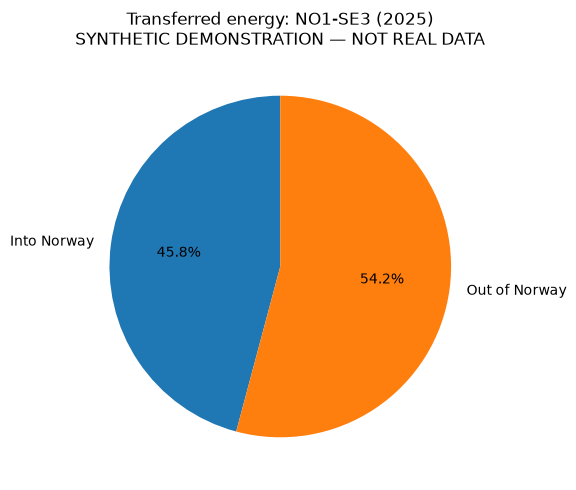

In [15]:
# Use a year that has January records for both chart requirements.
january_years = sorted(daily_pd.loc[daily_pd["month"] == 1, "year"].unique())
if not january_years:
    print("WARNING: no January data for the currently loaded source.")
CHART_YEAR = int(january_years[0] if january_years else sorted(daily_pd["year"].unique())[0])
CHART_CONNECTION = sorted(daily_pd["connection"].unique())[0]
source_label = "SYNTHETIC DEMONSTRATION — NOT REAL DATA" if DATA_MODE == "demo" else daily_pd["data_source"].iloc[0]

pie_data = (daily_pd[(daily_pd["year"] == CHART_YEAR) &
                     (daily_pd["connection"] == CHART_CONNECTION)]
            .groupby("direction")["energy_mwh"].sum()
            .reindex(["Into Norway", "Out of Norway"], fill_value=0))

if pie_data.sum() > 0:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(f"Transferred energy: {CHART_CONNECTION} ({CHART_YEAR})\n{source_label}")
    plt.tight_layout()
    plt.show()
else:
    print("No positive transferred energy for the selected border/year.")


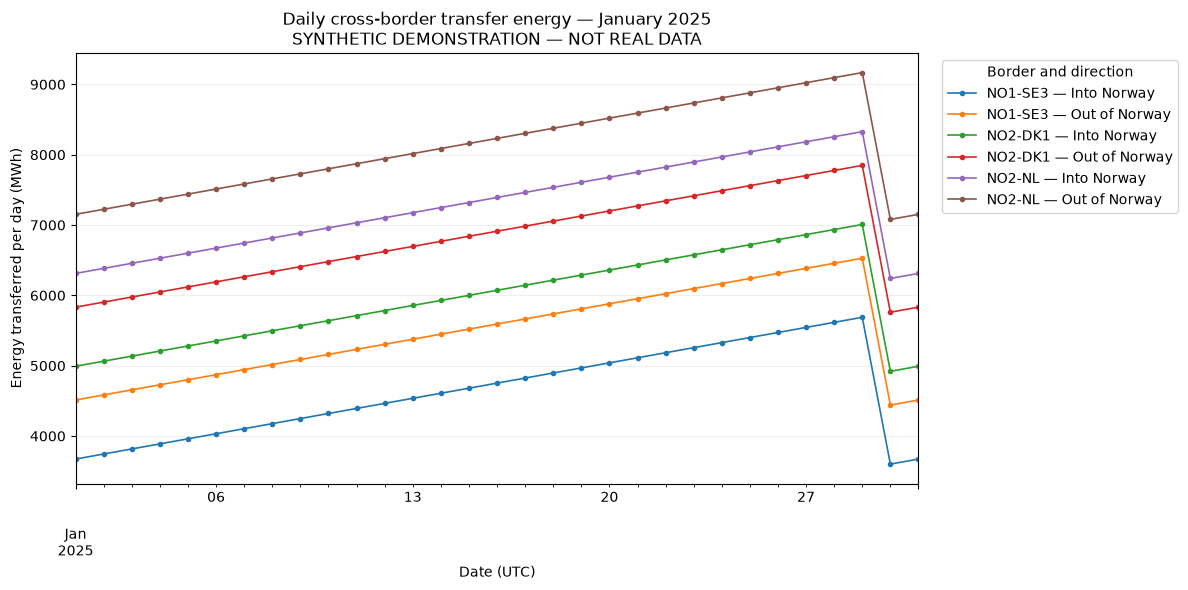

In [16]:
jan = daily_pd[(daily_pd["year"] == CHART_YEAR) & (daily_pd["month"] == 1)].copy()
if jan.empty:
    print("No January records for the selected year.")
else:
    jan["series"] = jan["connection"] + " — " + jan["direction"]
    wide = (jan.pivot_table(index="date", columns="series",
                            values="energy_mwh", aggfunc="sum").sort_index())
    ax = wide.plot(figsize=(12, 6), marker=".", linewidth=1.2)
    ax.set_title(f"Daily cross-border transfer energy — January {CHART_YEAR}\n{source_label}")
    ax.set_xlabel("Date (UTC)")
    ax.set_ylabel("Energy transferred per day (MWh)")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Border and direction")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


### Upload Spark data to MongoDB

In [17]:
from pymongo import MongoClient

if not MONGODB_URI:
    raise RuntimeError("Add MONGODB_URI to your local .env file before uploading.")

# Connect and verify access before changing any records.
client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=10000)
client.admin.command("ping")
collection = client["ind320_assignment2"][mongo_collection]

# Convert the Pandas rows to the simple document format used in Streamlit.
columns = ["connection", "direction", "date_utc", "year", "month",
           "energy_mwh", "data_source"]
documents = daily_pd[columns].to_dict("records")
for doc in documents:
    doc["year"] = int(doc["year"])
    doc["month"] = int(doc["month"])
    doc["energy_mwh"] = float(doc["energy_mwh"])

# Each run replaces this mode's collection (never the other mode).
collection.delete_many({})
collection.insert_many(documents)
print("MongoDB collection:", mongo_collection)
print("Documents uploaded:", collection.count_documents({}))

MongoDB collection: entsoe_daily_flows_demo
Documents uploaded: 4380


## Work log assignment 2

For this assignment I replaced the old CSV file with APIs and databases for both Jupyter notebook and streamlit. I started by installing and setting up Docker, Cassandra, Java and Spark. Setting up the Spark-Cassandra connection was especially challenging because Python kept failing (Python version 3.12.10), so I ended up having to change pyspark to version 3.5.9 instead of the recommended 3.5.1. There were a ton of other errors too that took forever to debug because the connections did not like my windows/python setup. With the help of chatgpt I eventually got through all the debugging.

For the ENTSO-E API, I created an account and requested a security token. Unfortunately, access had not been approved before the submission deadline. To demonstrate the remaining functionality, I used clearly identified synthetic electricity-transfer data. I inserted these data into Cassandra using Spark, retrieved and aggregated them using Spark, and created the required pie chart and line plots. I then uploaded the processed daily data to MongoDB Atlas. The code is prepared to use actual ENTSO-E measurements once API access becomes available.

I then updated the streamlit structure updating the dataLoader class to work with the NVE API rather than the old CSV. I also updated the pages to include things I saw during the peer review to make the plots nicer. Even with lots of help from ChatGPT on this assignment compared to the last one, it helped me understand APIs, local databases and cloud databases way better than before. The assignment is not completely finished yet as I'm still waiting for the actual ENTSO-E token, but I will complete it as soon as I get it.

## AI Usage

I used ChatGPT to assist with code development, debugging, and documentation throughout the assignment. AI was particularly useful for troubleshooting Spark and Cassandra compatibility issues, understanding API responses, and adapting my existing Jupyter Notebook and Streamlit code. I also used AI to help structure the database pipeline and prepare temporary demonstration data while waiting for ENTSO-E API access.

I reviewed and tested the generated code locally, made changes to simplify the implementation, and retained my existing DataLoader class and original plotting approach where appropriate.